In [1]:
!pip -q install zarr

import os, zipfile, urllib.request, math, copy, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import zarr
from google.colab import drive

drive.mount("/content/drive")

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name     :", torch.cuda.get_device_name(0))

CKPT_DIR = Path("/content/drive/MyDrive/pusht_diffusion/checkpoints")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print("checkpoints go to:", CKPT_DIR)

# data goes on Colab's fast local disk
DATA_DIR  = Path("/content/data")
ZARR_PATH = DATA_DIR / "pusht" / "pusht_cchi_v7_replay.zarr"
URL = "https://diffusion-policy.cs.columbia.edu/data/training/pusht.zip"

if not ZARR_PATH.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = DATA_DIR / "pusht.zip"
    print("Downloading data...")
    urllib.request.urlretrieve(URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
    found = list(DATA_DIR.rglob("*.zarr"))
    assert found, "No .zarr folder found after unzipping"
    ZARR_PATH = found[0]
print("data at:", ZARR_PATH)

Mounted at /content/drive
GPU available: True
GPU name     : Tesla T4
checkpoints go to: /content/drive/MyDrive/pusht_diffusion/checkpoints
data at: /content/data/pusht/pusht_cchi_v7_replay.zarr


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import zarr
from pathlib import Path

root = zarr.open(str(ZARR_PATH), mode="r")

action   = root["data"]["action"][:]
state    = root["data"]["state"][:]
keypoint = root["data"]["keypoint"][:]
episode_ends = root["meta"]["episode_ends"][:]

agent_pos = state[:, :2]
obs = np.concatenate([keypoint.reshape(len(keypoint), -1), agent_pos], axis=1)

print("obs:", obs.shape, " action:", action.shape, " episodes:", len(episode_ends))

obs: (25650, 20)  action: (25650, 2)  episodes: 206


In [3]:
def make_stats(arr):
    return {"min": arr.min(axis=0), "max": arr.max(axis=0)}

def normalize(x, stats):
    return 2 * (x - stats["min"]) / (stats["max"] - stats["min"]) - 1

def unnormalize(x_norm, stats):
    return (x_norm + 1) / 2 * (stats["max"] - stats["min"]) + stats["min"]

obs_stats    = make_stats(obs)
action_stats = make_stats(action)

obs_norm    = normalize(obs, obs_stats)
action_norm = normalize(action, action_stats)

In [4]:
print("normalized action: min", action_norm.min(axis=0), " max", action_norm.max(axis=0))
print("normalized obs   : min", obs_norm.min().round(3), " max", obs_norm.max().round(3))

# going back should give the original numbers
err_a = np.abs(unnormalize(action_norm, action_stats) - action).max()
err_o = np.abs(unnormalize(obs_norm, obs_stats) - obs).max()
print("round-trip error, action:", err_a, " obs:", err_o)

# save the stats for later notebooks (training and evaluation)
np.savez("norm_stats.npz",
         obs_min=obs_stats["min"], obs_max=obs_stats["max"],
         action_min=action_stats["min"], action_max=action_stats["max"])

normalized action: min [-1. -1.]  max [1. 1.]
normalized obs   : min -1.0  max 1.0
round-trip error, action: 7.6293945e-06  obs: 3.0517578e-05


In [5]:
T_o, T_p = 2, 16

starts  = np.concatenate([[0], episode_ends[:-1]])
lengths = episode_ends - starts

# for every row, remember where its own episode starts and ends
ep_start = np.repeat(starts, lengths)
ep_end   = np.repeat(episode_ends, lengths)      # exclusive end

def get_window(i):
    """i = row index of the 'current time t'. Returns (obs window, action window)."""
    s, e = ep_start[i], ep_end[i]
    obs_idx = np.clip(np.arange(i - T_o + 1, i + 1), s, e - 1)
    act_idx = np.clip(np.arange(i, i + T_p),         s, e - 1)
    return obs_norm[obs_idx], action_norm[act_idx]

In [6]:
for name, i in [("start of episode 0 ", starts[0]),
                ("middle of episode 0", starts[0] + 60),
                ("near the end       ", episode_ends[0] - 3)]:
    o, a = get_window(i)
    print(f"{name}: obs {o.shape}, action {a.shape}")

# at the start, both observations should be identical (padding)
o, a = get_window(starts[0])
print("start: the 2 observations are equal?", np.allclose(o[0], o[1]))

# in the middle, the window should match a direct slice
i = starts[0] + 60
o, a = get_window(i)
print("middle: actions match direct slice?", np.allclose(a, action_norm[i:i + T_p]))

# near the end, the last actions should repeat the final action of the episode
i = episode_ends[0] - 3
o, a = get_window(i)
print("end: last 3 action rows equal?", np.allclose(a[-1], a[-2]) and np.allclose(a[-2], a[-3]))

start of episode 0 : obs (2, 20), action (16, 2)
middle of episode 0: obs (2, 20), action (16, 2)
near the end       : obs (2, 20), action (16, 2)
start: the 2 observations are equal? True
middle: actions match direct slice? True
end: last 3 action rows equal? True


In [7]:
import torch
from torch.utils.data import Dataset, DataLoader

class PushTDataset(Dataset):
    def __len__(self):
        return len(obs_norm)

    def __getitem__(self, i):
        o, a = get_window(i)
        return {
            "obs":    torch.from_numpy(o.astype(np.float32)),   # (2, 20)
            "action": torch.from_numpy(a.astype(np.float32)),   # (16, 2)
        }

dataset = PushTDataset()
print("number of examples:", len(dataset))

sample = dataset[100]
print("one example:", sample["obs"].shape, sample["action"].shape)

number of examples: 25650
one example: torch.Size([2, 20]) torch.Size([16, 2])


In [8]:
BATCH_SIZE = 256
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

print("batches per epoch:", len(loader))

batch = next(iter(loader))
print("obs   :", batch["obs"].shape,    batch["obs"].dtype)
print("action:", batch["action"].shape, batch["action"].dtype)
print("obs value range   :", batch["obs"].min().item(), "to", batch["obs"].max().item())
print("action value range:", batch["action"].min().item(), "to", batch["action"].max().item())

batches per epoch: 101
obs   : torch.Size([256, 2, 20]) torch.float32
action: torch.Size([256, 16, 2]) torch.float32
obs value range   : -1.0 to 0.9858590364456177
action value range: -0.9559118151664734 to 1.0


In [9]:
import math
import numpy as np
import torch
import matplotlib.pyplot as plt

K = 100   # number of diffusion steps (Table 7: D-Iters Train = 100)

def squared_cosine_betas(K, s=0.008, max_beta=0.999):
    def abar(u):                      # u goes from 0 to 1
        return math.cos((u + s) / (1 + s) * math.pi / 2) ** 2
    betas = []
    for i in range(K):
        t1, t2 = i / K, (i + 1) / K
        betas.append(min(1 - abar(t2) / abar(t1), max_beta))
    return torch.tensor(betas, dtype=torch.float32)

betas = squared_cosine_betas(K)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)      # this is alpha-bar

for k in [0, 10, 25, 50, 75, 90, 99]:
    print(f"k={k:2d}  beta={betas[k].item():.4f}  alpha_bar={alphas_cumprod[k].item():.4f}")

k= 0  beta=0.0006  alpha_bar=0.9994
k=10  beta=0.0055  alpha_bar=0.9667
k=25  beta=0.0134  alpha_bar=0.8356
k=50  beta=0.0315  alpha_bar=0.4783
k=75  beta=0.0747  alpha_bar=0.1335
k=90  beta=0.1888  alpha_bar=0.0195
k=99  beta=0.9990  alpha_bar=0.0000


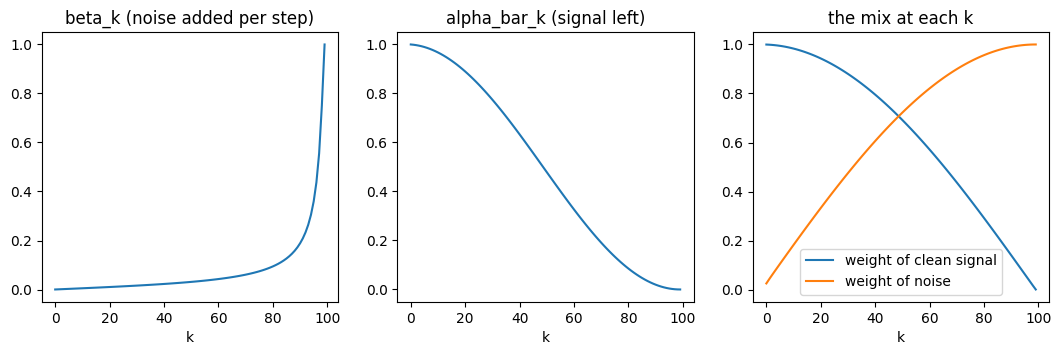

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].plot(betas.numpy())
axes[0].set_title("beta_k (noise added per step)")

axes[1].plot(alphas_cumprod.numpy())
axes[1].set_title("alpha_bar_k (signal left)")

axes[2].plot(torch.sqrt(alphas_cumprod).numpy(), label="weight of clean signal")
axes[2].plot(torch.sqrt(1 - alphas_cumprod).numpy(), label="weight of noise")
axes[2].set_title("the mix at each k")
axes[2].legend()

for ax in axes:
    ax.set_xlabel("k")
plt.show()

In [11]:
def timestep_embedding(k, dim=256):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half) / half)   # from fast to slow waves
    args = k[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

ks = torch.arange(K)
emb = timestep_embedding(ks)
print("embedding shape:", emb.shape)     # (100, 256)

embedding shape: torch.Size([100, 256])


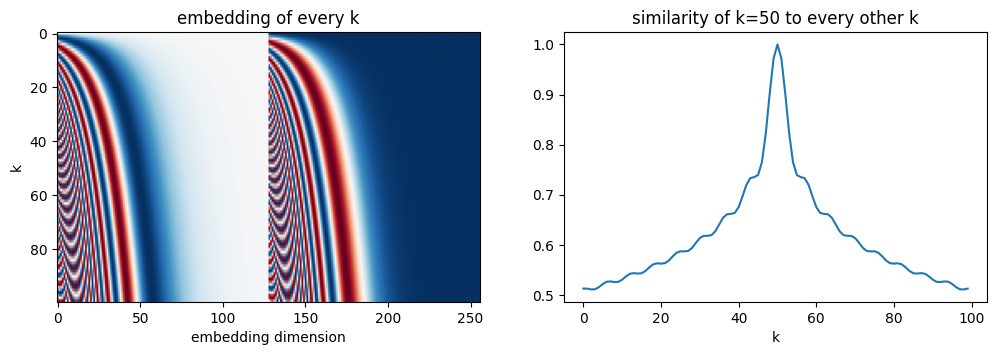

In [12]:
sim = torch.nn.functional.cosine_similarity(emb[50][None], emb, dim=-1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].imshow(emb.numpy(), aspect="auto", cmap="RdBu")
axes[0].set_xlabel("embedding dimension"); axes[0].set_ylabel("k")
axes[0].set_title("embedding of every k")
axes[1].plot(sim.numpy())
axes[1].set_xlabel("k"); axes[1].set_title("similarity of k=50 to every other k")
plt.show()

In [13]:
import torch.nn as nn

class Conv1dBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel=5, n_groups=8):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel, padding=kernel // 2),
            nn.GroupNorm(n_groups, out_ch),
            nn.Mish(),
        )
    def forward(self, x):
        return self.block(x)

class FiLMResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, cond_dim, kernel=5, n_groups=8):
        super().__init__()
        self.conv1 = Conv1dBlock(in_ch, out_ch, kernel, n_groups)
        self.conv2 = Conv1dBlock(out_ch, out_ch, kernel, n_groups)
        self.film  = nn.Linear(cond_dim, out_ch * 2)          # makes scale and shift
        self.res   = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, cond):
        out = self.conv1(x)                                    # (B, C, T)
        scale, shift = self.film(cond).chunk(2, dim=-1)        # each (B, C)
        out = scale[:, :, None] * out + shift[:, :, None]      # FiLM
        out = self.conv2(out)
        return out + self.res(x)

In [14]:
block = FiLMResBlock(in_ch=2, out_ch=64, cond_dim=40 + 256)    # 40 = 2 obs x 20, 256 = k embedding

x = torch.randn(4, 2, 16)                  # 4 noisy action blocks, (channels=2, time=16)
cond_a = torch.randn(4, 296)
cond_b = torch.randn(4, 296)

out_a = block(x, cond_a)
out_b = block(x, cond_b)

print("input :", x.shape)
print("output:", out_a.shape)
print("same x, different condition -> outputs differ?", not torch.allclose(out_a, out_b))
print("number of parameters:", sum(p.numel() for p in block.parameters()))

input : torch.Size([4, 2, 16])
output: torch.Size([4, 64, 16])
same x, different condition -> outputs differ? True
number of parameters: 59712


In [15]:
class ConditionalUnet1D(nn.Module):
    def __init__(self, action_dim=2, obs_dim=40, down_dims=(256, 512, 1024), embed_dim=256):
        super().__init__()
        self.embed_dim = embed_dim
        self.step_mlp = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 4), nn.Mish(), nn.Linear(embed_dim * 4, embed_dim))
        cond_dim = embed_dim + obs_dim

        dims = [action_dim, *down_dims]
        in_out = list(zip(dims[:-1], dims[1:]))

        self.down = nn.ModuleList()
        for i, (d_in, d_out) in enumerate(in_out):
            is_last = i == len(in_out) - 1
            self.down.append(nn.ModuleList([
                FiLMResBlock(d_in, d_out, cond_dim),
                FiLMResBlock(d_out, d_out, cond_dim),
                nn.Identity() if is_last else nn.Conv1d(d_out, d_out, 3, stride=2, padding=1),
            ]))

        mid = dims[-1]
        self.mid = nn.ModuleList([FiLMResBlock(mid, mid, cond_dim),
                                  FiLMResBlock(mid, mid, cond_dim)])

        self.up = nn.ModuleList()
        for d_in, d_out in reversed(in_out[1:]):
            self.up.append(nn.ModuleList([
                FiLMResBlock(d_out * 2, d_in, cond_dim),      # x2 because of the skip connection
                FiLMResBlock(d_in, d_in, cond_dim),
                nn.ConvTranspose1d(d_in, d_in, 4, stride=2, padding=1),
            ]))

        self.final = nn.Sequential(Conv1dBlock(down_dims[0], down_dims[0]),
                                   nn.Conv1d(down_dims[0], action_dim, 1))

    def forward(self, noisy_action, k, obs):
        # noisy_action: (B, 16, 2)   k: (B,)   obs: (B, 2, 20)
        x = noisy_action.transpose(1, 2)                          # (B, 2, 16)
        cond = torch.cat([self.step_mlp(timestep_embedding(k, self.embed_dim)),
                          obs.flatten(1)], dim=-1)                # (B, 296)
        skips = []
        for r1, r2, down in self.down:
            x = r1(x, cond); x = r2(x, cond)
            skips.append(x)
            x = down(x)
        for m in self.mid:
            x = m(x, cond)
        for r1, r2, up in self.up:
            x = torch.cat([x, skips.pop()], dim=1)
            x = r1(x, cond); x = r2(x, cond)
            x = up(x)
        return self.final(x).transpose(1, 2)                      # (B, 16, 2)

In [16]:
net = ConditionalUnet1D()                       # small version first

B = 4
a   = torch.randn(B, 16, 2)
k   = torch.randint(0, K, (B,))
obs = torch.randn(B, 2, 20)

out = net(a, k, obs)
print("output shape:", out.shape)
print("parameters  :", f"{sum(p.numel() for p in net.parameters()):,}")
print("observation matters?", not torch.allclose(out, net(a, k, torch.randn(B, 2, 20))))
print("k matters?          ", not torch.allclose(out, net(a, (k + 30) % K, obs)))

output shape: torch.Size([4, 16, 2])
parameters  : 65,783,298
observation matters? True
k matters?           True


In [17]:
def timestep_embedding(k, dim=256):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=k.device) / half)
    args = k[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

In [18]:
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

DOWN_DIMS = (256, 512, 1024)        # small net (65.8M). Paper-size is (512, 1024, 2048)
EPOCHS = 4500
STEPS_PER_EPOCH = len(loader)
TOTAL_STEPS = EPOCHS * STEPS_PER_EPOCH
WARMUP = 500
SAVE_EVERY = 50                     # epochs (the paper's checkpoint interval)

net = ConditionalUnet1D(down_dims=DOWN_DIMS).to(device)
ema_net = copy.deepcopy(net).eval()
for p in ema_net.parameters():
    p.requires_grad_(False)

ab = alphas_cumprod.to(device)
optimizer = torch.optim.AdamW(net.parameters(), lr=1e-4, weight_decay=1e-6)

def lr_lambda(step):
    if step < WARMUP:
        return (step + 1) / WARMUP
    progress = (step - WARMUP) / max(1, TOTAL_STEPS - WARMUP)
    return 0.5 * (1 + math.cos(math.pi * progress))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

def update_ema(step, max_decay=0.9999):
    decay = min(max_decay, (1 + step) / (10 + step))
    with torch.no_grad():
        for p_ema, p in zip(ema_net.parameters(), net.parameters()):
            p_ema.mul_(decay).add_(p, alpha=1 - decay)

def train_step(batch, step):
    obs_b = batch["obs"].to(device)
    a0    = batch["action"].to(device)
    B = a0.shape[0]
    k     = torch.randint(0, K, (B,), device=device)
    noise = torch.randn_like(a0)
    ab_k  = ab[k][:, None, None]
    noisy = torch.sqrt(ab_k) * a0 + torch.sqrt(1 - ab_k) * noise
    pred = net(noisy, k, obs_b)
    loss = torch.nn.functional.mse_loss(pred, noise)          # Eq. 5
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    scheduler.step()
    update_ema(step)
    return loss.item()

# ---- checkpoints -------------------------------------------------------
start_epoch, global_step, epoch_losses = 0, 0, []

def save_checkpoints(epoch):
    # 1) full state, overwritten each time: lets us resume after a disconnect
    tmp = CKPT_DIR / "latest.tmp"
    torch.save({"epoch": epoch, "step": global_step, "epoch_losses": epoch_losses,
                "net": net.state_dict(), "ema": ema_net.state_dict(),
                "opt": optimizer.state_dict(), "sched": scheduler.state_dict()}, tmp)
    tmp.replace(CKPT_DIR / "latest.pt")
    # 2) small EMA-only snapshots (half precision) for evaluation later:
    #    every 250 epochs, plus the last 10 checkpoints of the run
    if epoch % 250 == 0 or epoch > EPOCHS - 500:
        ema16 = {k_: v.half() for k_, v in ema_net.state_dict().items()}
        torch.save({"epoch": epoch, "ema": ema16, "down_dims": DOWN_DIMS},
                   CKPT_DIR / f"ema_epoch_{epoch:04d}.pt")

latest = CKPT_DIR / "latest.pt"
if latest.exists():
    ck = torch.load(latest, map_location=device)
    net.load_state_dict(ck["net"]);  ema_net.load_state_dict(ck["ema"])
    optimizer.load_state_dict(ck["opt"]);  scheduler.load_state_dict(ck["sched"])
    start_epoch, global_step, epoch_losses = ck["epoch"], ck["step"], ck["epoch_losses"]
    print(f"resumed from epoch {start_epoch} (step {global_step})")
else:
    print("no checkpoint found: starting from scratch")
print(f"steps per epoch: {STEPS_PER_EPOCH},  total steps: {TOTAL_STEPS:,}")

device: cuda
resumed from epoch 600 (step 60600)
steps per epoch: 101,  total steps: 454,500


In [19]:
def benchmark(n=40, warm=5):
    it = iter(loader)
    for i in range(warm):                      # warm-up steps, not timed
        train_step(next(it), i)
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for i in range(n):
        train_step(next(it), warm + i)
    if device == "cuda":
        torch.cuda.synchronize()
    s = (time.time() - t0) / n
    print(f"{s:.3f} s/step  |  {s * STEPS_PER_EPOCH / 60:.1f} min/epoch")
    print(f"projected time for {EPOCHS} epochs: {s * TOTAL_STEPS / 3600:.1f} hours")

benchmark()

0.304 s/step  |  0.5 min/epoch
projected time for 4500 epochs: 38.4 hours


In [ ]:
def run_training(stop_after_hours=None):
    global global_step
    t_start = time.time()
    for epoch in range(start_epoch + 1, EPOCHS + 1):
        net.train()
        losses = []
        for batch in loader:
            losses.append(train_step(batch, global_step))
            global_step += 1
        epoch_losses.append(float(np.mean(losses)))

        if epoch == start_epoch + 1 or epoch % 10 == 0:
            done = epoch - start_epoch
            elapsed = (time.time() - t_start) / 3600
            left = elapsed / done * (EPOCHS - epoch)
            print(f"epoch {epoch:4d}/{EPOCHS}  loss {epoch_losses[-1]:.4f}  "
                  f"lr {scheduler.get_last_lr()[0]:.2e}  "
                  f"elapsed {elapsed:.2f}h  est. remaining {left:.1f}h")

        out_of_time = stop_after_hours and (time.time() - t_start) / 3600 >= stop_after_hours
        if epoch % SAVE_EVERY == 0 or epoch == EPOCHS or out_of_time:
            save_checkpoints(epoch)
            print(f"  -> checkpoint saved at epoch {epoch}")
        if out_of_time:
            print("stopping as requested; rerun Cell B and then this cell to continue")
            break

run_training()

epoch  601/4500  loss 0.0063  lr 9.57e-05  elapsed 0.01h  est. remaining 33.9h
epoch  610/4500  loss 0.0060  lr 9.56e-05  elapsed 0.09h  est. remaining 35.8h
epoch  620/4500  loss 0.0060  lr 9.54e-05  elapsed 0.18h  est. remaining 35.9h
epoch  630/4500  loss 0.0062  lr 9.53e-05  elapsed 0.28h  est. remaining 35.8h
epoch  640/4500  loss 0.0057  lr 9.51e-05  elapsed 0.37h  est. remaining 35.7h
epoch  650/4500  loss 0.0060  lr 9.50e-05  elapsed 0.46h  est. remaining 35.6h
  -> checkpoint saved at epoch 650
epoch  660/4500  loss 0.0060  lr 9.48e-05  elapsed 0.56h  est. remaining 35.7h
epoch  670/4500  loss 0.0060  lr 9.47e-05  elapsed 0.65h  est. remaining 35.6h
epoch  680/4500  loss 0.0058  lr 9.45e-05  elapsed 0.74h  est. remaining 35.5h
epoch  690/4500  loss 0.0058  lr 9.44e-05  elapsed 0.84h  est. remaining 35.4h
epoch  700/4500  loss 0.0061  lr 9.42e-05  elapsed 0.93h  est. remaining 35.3h
  -> checkpoint saved at epoch 700
epoch  710/4500  loss 0.0053  lr 9.40e-05  elapsed 1.02h  est

In [19]:
alphas_d = alphas.to(device)
betas_d  = betas.to(device)
ab_prev  = torch.cat([torch.ones(1), alphas_cumprod[:-1]]).to(device)

@torch.no_grad()
def sample(model, obs_b):
    """obs_b: (B, 2, 20) normalized observations. Returns (B, 16, 2) normalized actions."""
    B = obs_b.shape[0]
    x = torch.randn(B, 16, 2, device=device)                       # pure noise
    for k in reversed(range(K)):
        kk  = torch.full((B,), k, device=device, dtype=torch.long)
        eps = model(x, kk, obs_b)

        x0 = (x - torch.sqrt(1 - ab[k]) * eps) / torch.sqrt(ab[k])  # estimate of the clean action
        x0 = x0.clamp(-1, 1)

        coef1 = torch.sqrt(ab_prev[k]) * betas_d[k] / (1 - ab[k])
        coef2 = torch.sqrt(alphas_d[k]) * (1 - ab_prev[k]) / (1 - ab[k])
        mean  = coef1 * x0 + coef2 * x

        if k > 0:
            var = betas_d[k] * (1 - ab_prev[k]) / (1 - ab[k])
            x = mean + torch.sqrt(var) * torch.randn_like(x)
        else:
            x = mean
    return x